Generating concentric circles data...
Running K-Means...


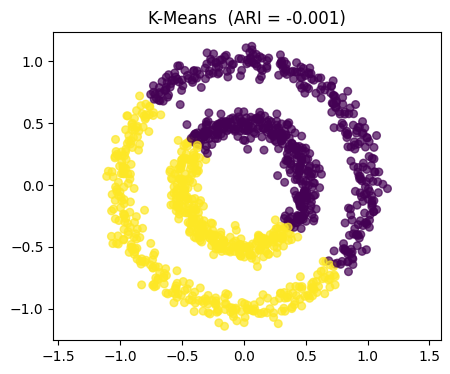

Running Spectral Clustering...
Building similarity graph...
Computing eigenvectors...


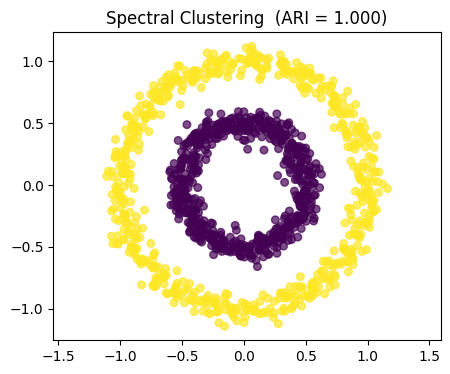

Final ARI comparison → K-Means: -0.001  |  Spectral: 1.000


In [1]:
# Install if needed
# !pip install scikit-learn numpy matplotlib

from sklearn.datasets import make_circles
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np
import matplotlib.pyplot as plt

# ────────────────────────────────────────────────
# 1. Generate concentric circles dataset
# ────────────────────────────────────────────────
print("Generating concentric circles data...")
X, y_true = make_circles(
    n_samples=1200,
    noise=0.06,
    factor=0.5,
    random_state=42
)

# ────────────────────────────────────────────────
# 2. K-Means (baseline - expected to fail)
# ────────────────────────────────────────────────
print("Running K-Means...")
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X)
ari_kmeans = adjusted_rand_score(y_true, labels_kmeans)

plt.figure(figsize=(5,4))
plt.scatter(X[:,0], X[:,1], c=labels_kmeans, s=30, cmap='viridis', alpha=0.7)
plt.title(f"K-Means  (ARI = {ari_kmeans:.3f})")
plt.axis('equal')
plt.show()

# ────────────────────────────────────────────────
# 3. Spectral Clustering – from scratch
# ────────────────────────────────────────────────
def spectral_clustering_from_scratch(X, n_clusters=2, sigma=0.12):
    n = X.shape[0]
    
    # Build similarity matrix (Gaussian kernel)
    print("Building similarity graph...")
    W = np.zeros((n, n))
    for i in range(n):
        for j in range(i+1, n):          # symmetric → fill upper triangle
            dist = np.linalg.norm(X[i] - X[j])
            sim = np.exp(-dist**2 / (2 * sigma**2))
            W[i,j] = sim
            W[j,i] = sim
    
    # Degree matrix
    D = np.diag(np.sum(W, axis=1))
    
    # Laplacian
    L = D - W
    
    # Eigen decomposition (smallest eigenvalues)
    print("Computing eigenvectors...")
    eigvals, eigvecs = np.linalg.eigh(L)
    
    # Take the k smallest non-zero eigenvectors
    idx = np.argsort(eigvals)[1 : n_clusters+1]
    embedding = eigvecs[:, idx]
    
    # Final clustering in embedding space
    kmeans_embed = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans_embed.fit_predict(embedding)
    
    return labels

# Run Spectral
print("Running Spectral Clustering...")
labels_spectral = spectral_clustering_from_scratch(X, n_clusters=2, sigma=0.12)
ari_spectral = adjusted_rand_score(y_true, labels_spectral)

plt.figure(figsize=(5,4))
plt.scatter(X[:,0], X[:,1], c=labels_spectral, s=30, cmap='viridis', alpha=0.7)
plt.title(f"Spectral Clustering  (ARI = {ari_spectral:.3f})")
plt.axis('equal')
plt.show()

print(f"Final ARI comparison → K-Means: {ari_kmeans:.3f}  |  Spectral: {ari_spectral:.3f}")